# Module 04: Electromagnetic Wave Laboratory

## Introduction & Learning Objectives
When electric and magnetic fields vary in time, Maxwell's equations couple them together: a time-varying magnetic field induces a curling electric field ($\nabla \times \mathbf{E} = -\partial \mathbf{B}/\partial t$), and a time-varying electric field induces a curling magnetic field ($\nabla \times \mathbf{B} = \mu_0 \varepsilon_0 \partial \mathbf{E}/\partial t$). In vacuum, these self-sustaining disturbances propagate at the speed of light $c = 1/\sqrt{\mu_0\varepsilon_0} = 299,792,458\ \text{m/s}$.

**Learning Objectives:**
1. Visualize the mutually perpendicular oscillations of $\mathbf{E}(x, t)$, $\mathbf{B}(x, t)$, and propagation vector $\mathbf{k}$ in a linearly polarized vacuum plane wave.
2. Understand why frequency $f$ and wavelength $\lambda$ cannot be varied independently in vacuum ($c = f\lambda$), and why electric and magnetic amplitudes are strictly locked by $|\mathbf{E}| = c|\mathbf{B}|$.
3. Analyze the instantaneous Poynting energy flux vector $\mathbf{S}(x, t) = \frac{1}{\mu_0}(\mathbf{E} \times \mathbf{B})$ and time-averaged irradiance $\langle S \rangle = \frac{E_0^2}{2 Z_0}$.
4. Contrast vacuum wave propagation with propagation in dielectric media ($v_p = c / n$).

---

## Physical Model & Enforced Vacuum Constraints

For a plane electromagnetic wave propagating along $+x$ in vacuum:

$$\mathbf{E}(x, t) = E_0 \cos(kx - \omega t + \phi)\,\hat{\mathbf{y}}, \qquad \mathbf{B}(x, t) = B_0 \cos(kx - \omega t + \phi)\,\hat{\mathbf{z}}$$

where:
- **Dispersion Constraint**: $c = f\lambda$, $k = 2\pi / \lambda$, $\omega = 2\pi f$.
- **Amplitude Constraint**: $B_0 = E_0 / c$ at every instant and spatial location.
- **Wave Impedance**: $Z_0 = \mu_0 c \approx 376.73\ \Omega$.

In `invisible_physics.waves.PlaneWaveVacuum`, passing contradictory $(f, \lambda)$ values where $f\lambda \neq c$ raises a `ValueError` so nonphysical vacuum configurations are impossible to construct accidentally.

In [1]:
import sys
from pathlib import Path
for _cand in (Path.cwd() / "src", Path.cwd().parent / "src"):
    if _cand.is_dir() and str(_cand.resolve()) not in sys.path:
        sys.path.insert(0, str(_cand.resolve()))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

from invisible_physics import (
    C_VACUUM,
    Z_0_VACUUM,
    PlaneWaveVacuum,
    apply_scientific_style,
    create_electromagnetic_wave_animation,
    evaluate_plane_wave_1d,
    plot_electromagnetic_wave_2d_panels,
    plot_electromagnetic_wave_3d,
)

apply_scientific_style()
print(f"Speed of light in vacuum c         = {C_VACUUM:.1f} m/s")
print(f"Free-space wave impedance Z_0      = {Z_0_VACUUM:.4f} Ohms")

Speed of light in vacuum c         = 299792458.0 m/s
Free-space wave impedance Z_0      = 376.7303 Ohms


---
## 1. 3D Transverse Plane Wave & Synchronized 2D Waveforms

Let us construct a $100\ \text{MHz}$ VHF radio wave in vacuum with electric-field amplitude $E_0 = 120\ \text{V/m}$. `PlaneWaveVacuum.from_frequency()` automatically computes the exact vacuum wavelength $\lambda = c / f \approx 2.9979\ \text{m}$ and magnetic amplitude $B_0 = E_0 / c \approx 400.28\ \text{nT}$.

Frequency f                : 100.00 MHz
Derived wavelength lambda  : 2.997925 m
Electric amplitude E_0     : 120.00 V/m
Magnetic amplitude B_0     : 400.2769 nT
Time-averaged flux <S>     : 19.1118 W/m²


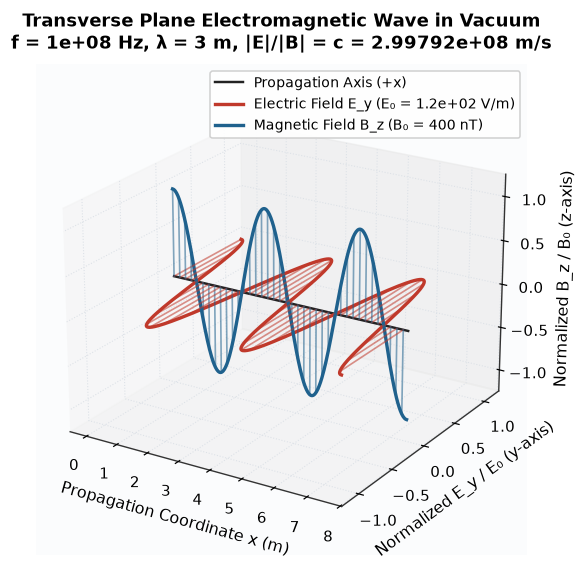

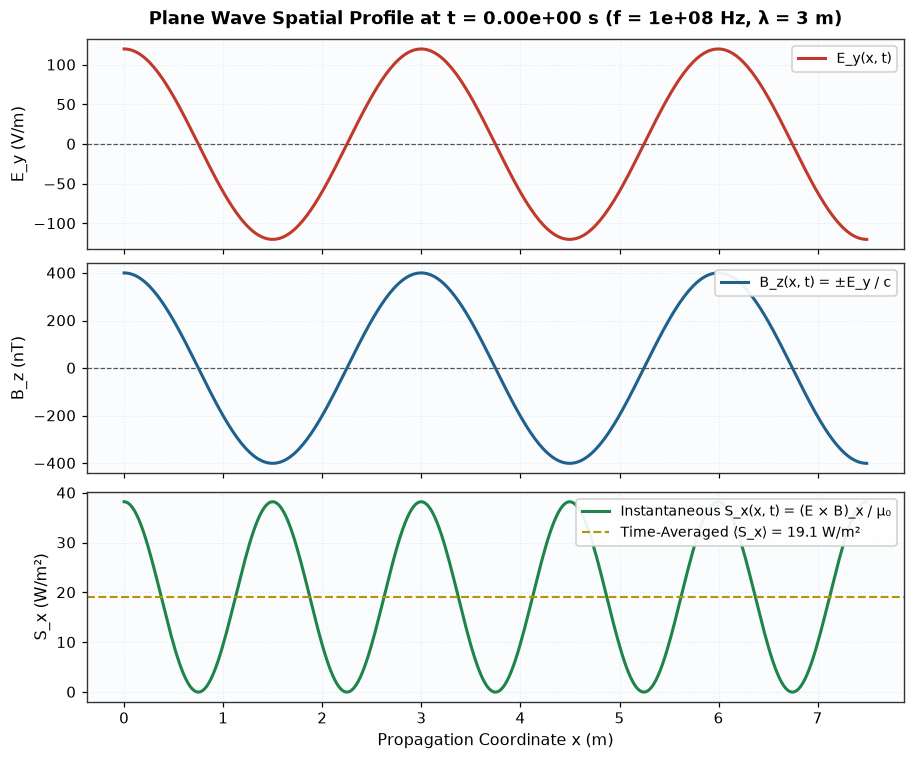

In [2]:
wave_100mhz = PlaneWaveVacuum.from_frequency(frequency_hz=100.0e6, e0_v_per_m=120.0, phase_rad=0.0)
x_coords = np.linspace(0.0, 2.5 * wave_100mhz.wavelength_m, 350)
profile_t0 = evaluate_plane_wave_1d(wave_100mhz, x_coords, t_s=0.0)

print(f"Frequency f                : {wave_100mhz.frequency_hz * 1e-6:.2f} MHz")
print(f"Derived wavelength lambda  : {wave_100mhz.wavelength_m:.6f} m")
print(f"Electric amplitude E_0     : {wave_100mhz.e0_v_per_m:.2f} V/m")
print(f"Magnetic amplitude B_0     : {wave_100mhz.b0_tesla * 1e9:.4f} nT")
print(f"Time-averaged flux <S>     : {wave_100mhz.time_averaged_intensity_w_per_m2:.4f} W/m²")

fig_3d, _ = plot_electromagnetic_wave_3d(profile_t0)
plt.show()

fig_2d, _ = plot_electromagnetic_wave_2d_panels(profile_t0)
plt.show()

### Interpretation
- **In-Phase Transverse Oscillations**: Unlike a mechanical standing wave, the electric field $E_y(x, t)$ and magnetic field $B_z(x, t)$ of a traveling plane electromagnetic wave reach their crests, troughs, and zero-crossings **in phase** at the same positions and times.
- **Unidirectional Energy Transport**: Because $E_y$ and $B_z$ reverse sign simultaneously every half-wavelength, their cross product $S_x = E_y B_z / \mu_0 = (E_0^2 / Z_0)\cos^2(kx - \omega t)$ is **non-negative everywhere**, oscillating at frequency $2f$ around the mean intensity $\langle S_x \rangle = 19.11\ \text{W/m}^2$.

---
## 2. Time Evolution (Wave Propagation Snapshot Sequence)

By evaluating the wave at fractions of its oscillation period $T = 1/f = 10\ \text{ns}$ ($t = 0, T/4, T/2, 3T/4$), we observe the phase crests translating in the $+x$ direction at speed $v_p = \lambda / T = c$.

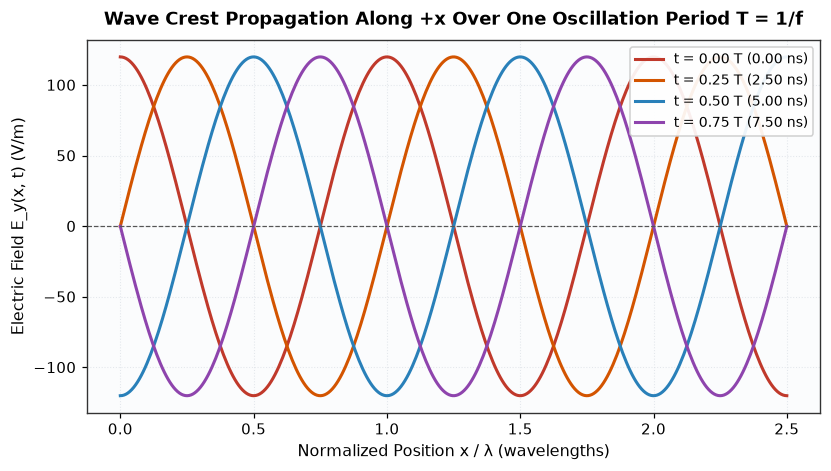

In [3]:
T = wave_100mhz.period_s
time_fractions = [0.0, 0.25, 0.50, 0.75]

fig, ax = plt.subplots(figsize=(8.6, 4.4))
colors = ["#c0392b", "#d35400", "#2980b9", "#8e44ad"]

for frac, col in zip(time_fractions, colors):
    prof = evaluate_plane_wave_1d(wave_100mhz, x_coords, t_s=frac * T)
    ax.plot(
        x_coords / wave_100mhz.wavelength_m,
        prof.Ey,
        lw=2.0,
        color=col,
        label=f"t = {frac:.2f} T ({frac * T * 1e9:.2f} ns)",
    )

ax.axhline(0.0, color="#555555", lw=0.8, ls="--")
ax.set_xlabel("Normalized Position x / λ (wavelengths)")
ax.set_ylabel("Electric Field E_y(x, t) (V/m)")
ax.set_title("Wave Crest Propagation Along +x Over One Oscillation Period T = 1/f")
ax.legend(loc="upper right")
plt.show()

---
## 3. Vacuum vs. Dielectric Material Propagation

In a non-magnetic lossless dielectric medium (such as optical glass with refractive index $n = \sqrt{\varepsilon_r} \approx 1.50$), the frequency $f$ remains invariant across the boundary, while the phase speed and wavelength decrease by factor $n$:

$$v_p = \frac{c}{n}, \qquad \lambda_{\text{medium}} = \frac{\lambda_{\text{vacuum}}}{n}, \qquad |\mathbf{E}| = v_p |\mathbf{B}| = \frac{c}{n}|\mathbf{B}|$$

### Optional Interactive HTML5 Wave Animation
Below we generate a smooth 2D animation of the traveling electromagnetic wave over one full period $T = 1/f$ using `create_electromagnetic_wave_animation()`.

In [4]:
fig_anim, anim = create_electromagnetic_wave_animation(wave_100mhz, n_wavelengths=2.0, n_frames=16, interval_ms=70)
plt.close(fig_anim)
display(HTML(anim.to_jshtml()))

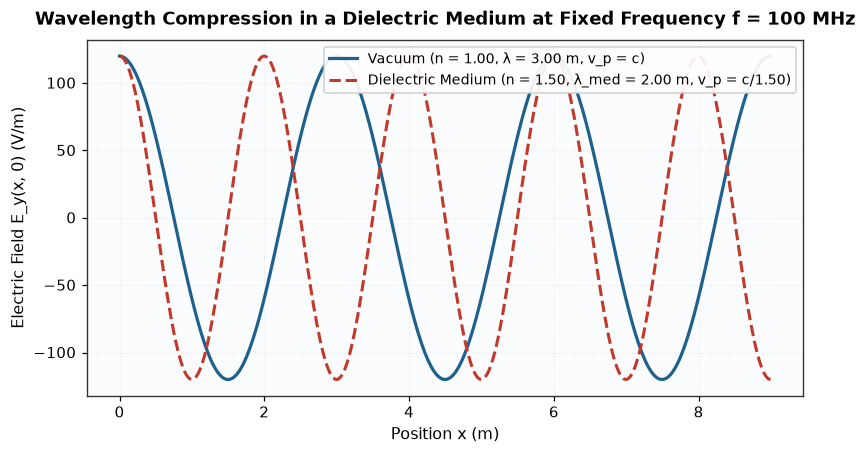

In [5]:
n_glass = 1.50
x_norm = np.linspace(0.0, 3.0 * wave_100mhz.wavelength_m, 400)
k_vac = wave_100mhz.wavenumber_rad_per_m
k_glass = n_glass * k_vac

ey_vac = wave_100mhz.e0_v_per_m * np.cos(k_vac * x_norm)
ey_glass = wave_100mhz.e0_v_per_m * np.cos(k_glass * x_norm)

fig, ax = plt.subplots(figsize=(8.4, 4.2))
ax.plot(x_norm, ey_vac, lw=2.1, color="#1f618d", label=f"Vacuum (n = 1.00, λ = {wave_100mhz.wavelength_m:.2f} m, v_p = c)")
ax.plot(x_norm, ey_glass, "--", lw=2.0, color="#c0392b", label=f"Dielectric Medium (n = {n_glass:.2f}, λ_med = {wave_100mhz.wavelength_m / n_glass:.2f} m, v_p = c/{n_glass:.2f})")
ax.set_xlabel("Position x (m)")
ax.set_ylabel("Electric Field E_y(x, 0) (V/m)")
ax.set_title("Wavelength Compression in a Dielectric Medium at Fixed Frequency f = 100 MHz")
ax.legend(loc="upper right")
plt.show()

---
## 4. Interactive Plane Wave Explorer (Physically Linked Parameters)

Adjust the frequency $f$ (in MHz), electric-field amplitude $E_0$ (in V/m), phase $\phi$ (in degrees), and propagation direction (`+x` or `-x`). Wavelength $\lambda = c / f$ and magnetic amplitude $B_0 = E_0 / c$ update automatically to preserve Maxwell's equations in vacuum.

In [6]:
import sys
from pathlib import Path
for _cand in (Path.cwd() / "src", Path.cwd().parent / "src"):
    if _cand.is_dir() and str(_cand.resolve()) not in sys.path:
        sys.path.insert(0, str(_cand.resolve()))
import numpy as np
import matplotlib.pyplot as plt
from invisible_physics import *

import ipywidgets as widgets
from IPython.display import display


def update_wave_explorer(
    freq_mhz: float = 100.0,
    e0_v_per_m: float = 100.0,
    phase_deg: float = 0.0,
    direction: str = "+x",
) -> None:
    wave = PlaneWaveVacuum.from_frequency(
        frequency_hz=freq_mhz * 1e6,
        e0_v_per_m=e0_v_per_m,
        phase_rad=np.radians(phase_deg),
        propagation_axis=direction,  # type: ignore[arg-type]
    )
    # Fix spatial window to 6.0 meters so wavelength changes are visually clear
    x_win = np.linspace(0.0, 6.0, 350)
    prof = evaluate_plane_wave_1d(wave, x_win, t_s=0.0)
    plot_electromagnetic_wave_3d(prof)
    plt.show()


w_freq = widgets.FloatSlider(value=100.0, min=30.0, max=300.0, step=10.0, description="f (MHz):")
w_e0 = widgets.FloatSlider(value=100.0, min=10.0, max=300.0, step=10.0, description="E₀ (V/m):")
w_phi = widgets.FloatSlider(value=0.0, min=-180.0, max=180.0, step=15.0, description="Phase φ (°):")
w_dir = widgets.Dropdown(options=["+x", "-x"], value="+x", description="Direction:")

ui_wave = widgets.HBox([w_freq, w_e0, w_phi, w_dir])
out_wave = widgets.interactive_output(
    update_wave_explorer,
    {"freq_mhz": w_freq, "e0_v_per_m": w_e0, "phase_deg": w_phi, "direction": w_dir},
)
display(ui_wave, out_wave)

Output()

---
## Summary & Further Experiments
- **What we learned**: In vacuum, electromagnetic plane waves satisfy $c = f\lambda$, $|\mathbf{E}| = c|\mathbf{B}|$, and $\mathbf{E} \perp \mathbf{B} \perp \mathbf{k}$, carrying energy flux $\mathbf{S} = (\mathbf{E} \times \mathbf{B}) / \mu_0$.
- **Next steps**: Open [`05_physics_experiments.ipynb`](05_physics_experiments.ipynb) for seven structured, hypothesis-driven quantitative experiments across all modules.